# ESS LLRF anomaly detection on a feature store

Three programs that share only the feature store and the model registry:

| Step | Program | Writes | Reads |
|---|---|---|---|
| Feature | `feature_pipeline.py`, `generators/ess_sds_stream.py` | `ess_sds_events`, `ess_waveform_features` | public sample |
| Training | `training_pipeline.py` | model `ess_llrf_anomaly` | feature view `ess_llrf_anomaly` |
| Inference | `inference_pipeline.py`, `predictor.py` | deployment `essanomaly` | online features, model |

This notebook runs every step locally on the 210-cycle public sample. The cluster calls are shown as markdown, run them from the scripts.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "generators")
from feature_pipeline import KEYS, SAMPLE_URL, build, load_sample
from ess_sds_stream import Replay
from training_pipeline import holdout_keys

## 1. Feature pipeline

One row is one acquisition cycle of one RF chain, five cycles per post-mortem event. `I` looks like an amplitude envelope (fill, flat-top, decay) and `Q` like a phase trace; the case holder has not confirmed either, so the features keep the column names.

In [2]:
sample = load_sample()
events, features = build(sample)
print(f"{events.event_id.nunique()} events, {len(events)} cycles")
events.head(3)

42 events, 210 cycles


,event_id,cycle_id,event_ts,source_tar,pv_base,trig_code,trig_user_tag,beam_mode,beam_state,beam_present,synthetic,source_event_id,injected_anomaly
0,16096681849,16096681837,2026-06-08 08:03:58.781086192+00:00,SDS_Data_20260607_0300_20260608_1030_DD_160966...,MBL-090RFC:RFS-DIG-101:Dwn0-CmpSDS-PMData,14,0,Probe,BEAM_INHIBIT,False,False,16096681849,False
1,16096681849,16096681838,2026-06-08 08:03:58.781086192+00:00,SDS_Data_20260607_0300_20260608_1030_DD_160966...,MBL-090RFC:RFS-DIG-101:Dwn0-CmpSDS-PMData,14,0,Probe,BEAM_INHIBIT,False,False,16096681849,False
2,16096681849,16096681839,2026-06-08 08:03:58.781086192+00:00,SDS_Data_20260607_0300_20260608_1030_DD_160966...,MBL-090RFC:RFS-DIG-101:Dwn0-CmpSDS-PMData,14,0,Probe,BEAM_INHIBIT,False,False,16096681849,False


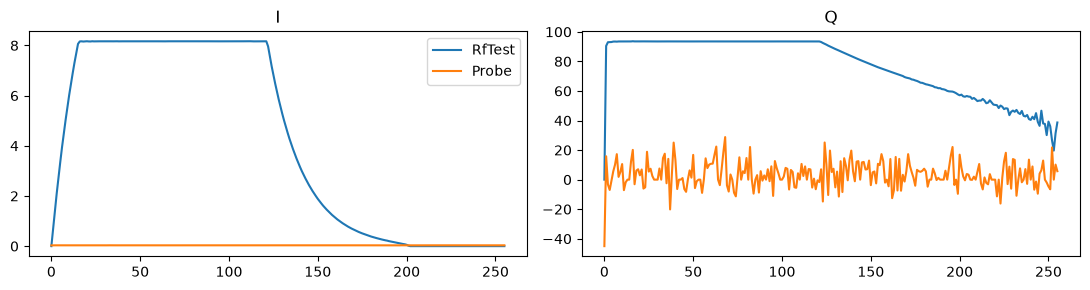

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for mode in ["RfTest", "Probe"]:
    row = sample[sample.beam_mode == mode].iloc[0]
    ax[0].plot(row.I, label=mode)
    ax[1].plot(row.Q, label=mode)
ax[0].set_title("I"); ax[1].set_title("Q"); ax[0].legend()
plt.tight_layout()

In [4]:
features.drop(columns=KEYS + ["event_ts"]).describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
i_max,7.167503,2.398887,0.034138,8.185481
i_flat_level,7.161783,2.399116,0.032678,8.164475
i_flat_len,111.971429,43.565923,47.000000,252.000000
i_flat_ripple,0.004191,0.004706,0.002619,0.020908
i_droop,0.000398,0.001184,-0.008396,0.007025
i_rise,13.228571,5.815763,0.000000,59.000000
i_fall,42.019048,11.262404,1.000000,109.000000
i_tail_noise,0.000083,0.000262,0.000000,0.001243
q_flat_mean,71.538896,42.124236,-17.908660,93.517559
q_flat_std,0.896205,2.653799,0.020723,9.933513


On the cluster, the same two frames become online feature groups keyed on `(event_id, cycle_id)` with event time `event_ts`:

```bash
python feature_pipeline.py --insert
```

## 2. Synthetic stream

Each synthetic event is a real event with a fresh id and timestamp, an event-wide gain on `I` and offset on `Q` drawn from the spread the real cycles show, and `synthetic=True`. `--hot` adds the one invented signal: a linear droop of `I` across the flat-top of the last cycle.

next event in 3600 s of real time


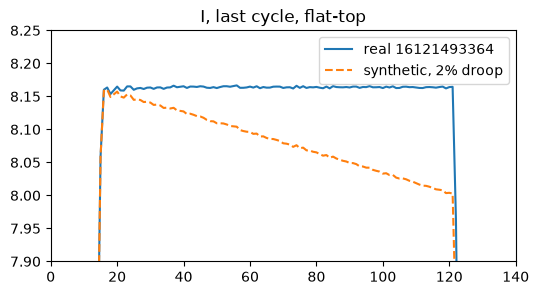

In [5]:
replay = Replay(SAMPLE_URL, hot=1.0, droop=0.02, seed=3)
event, gap = replay.next()
source = sample[sample.event_id == event.source_event_id.iloc[0]].sort_values("cycle_id")
plt.figure(figsize=(6, 3))
plt.plot(source.I.iloc[-1], label=f"real {source.event_id.iloc[0]}")
plt.plot(event.I.iloc[-1], "--", label="synthetic, 2% droop")
plt.xlim(0, 140); plt.ylim(7.9, 8.25); plt.legend(); plt.title("I, last cycle, flat-top")
print(f"next event in {gap:.0f} s of real time")

On the cluster the generator writes online only, into the same two groups:

```bash
python generators/ess_sds_stream.py --insert --follow --hot 0.2
```

## 3. Training pipeline

The split is the challenge's `holdout_ids.json`, mapped from row positions to keys. On the cluster the frame comes from the feature view:

```python
fv = fs.get_or_create_feature_view(name="ess_llrf_anomaly", version=1,
    query=features_fg.select_except(["event_id", "cycle_id", "event_ts"]))
X, _ = fv.training_data(start_time="2026-06-01", end_time="2026-07-01", primary_key=True)
```

In [6]:
X = features.drop(columns="event_ts")
holdout = X.set_index(KEYS).index.isin(holdout_keys(SAMPLE_URL))
X = X.drop(columns=KEYS)
model = make_pipeline(StandardScaler(), IsolationForest(n_estimators=300, contamination=0.05, random_state=42))
model.fit(X[~holdout])
print(f"train {(~holdout).sum()} cycles, holdout {holdout.sum()} cycles")
print(f"holdout mean score {-model.score_samples(X[holdout]).mean():.4f}, "
      f"flagged {(model.predict(X[holdout]) == -1).mean():.1%}")

train 168 cycles, holdout 42 cycles
holdout mean score 0.4491, flagged 9.5%


## 4. Inference

The deployment receives keys, looks up features online, returns `[score, flagged]`:

```python
deployment.predict(inputs=[{"event_id": 16096686207, "cycle_id": 16096686195}])
```

Locally, score 200 synthetic events, 30% with an injected droop. `injected_anomaly` is the truth for synthetic rows only; the model never sees it.

In [7]:
replay = Replay(SAMPLE_URL, hot=0.3, droop=0.02, seed=7)
live = pd.concat([replay.next()[0] for _ in range(200)], ignore_index=True)
_, live_features = build(live)
live["score"] = -model.score_samples(live_features[X.columns])
live["flagged"] = model.predict(live_features[X.columns]) == -1
drooped = live.injected_anomaly & (live.cycle_id == live.groupby("event_id").cycle_id.transform("max"))
print(f"AUC drooped cycles vs the rest: {roc_auc_score(drooped, live.score):.3f}")
live.groupby(drooped.rename("drooped"))[["score", "flagged"]].mean()

AUC drooped cycles vs the rest: 0.958


,score,flagged
drooped,,
False,0.432408,0.039404
True,0.597362,0.245902
